# Demo 14 — Atmosphere models and custom limb darkening

This notebook shows how to choose an atmosphere for each star, provide passband-specific limb-darkening (LD) coefficients, measure their effect on an eclipse, and carry the same choices into a fitting task.

Run all cells in order in the repository's ELISA environment (Python 3.11+). The main example uses black bodies and explicit LD coefficients for **both** stars, so it does not require downloaded atmosphere or LD grids. No observations or results from another notebook are needed. The optional CK04 example requires external tables.

The coefficients and the 55,000 K primary below are illustrative, not a calibrated model of a particular binary. A black body is a continuum approximation; it does not reproduce atmosphere spectral lines or replace an appropriate hot-star atmosphere.

In [1]:
%matplotlib inline
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

from elisa import settings, BinarySystem, Observer
from elisa.analytics import LCData, LCBinaryAnalyticsTask

original_ld_law = settings.LIMB_DARKENING_LAW
settings.configure(
    LIMB_DARKENING_LAW='logarithmic',
)
passband = 'TESS'
phases = np.linspace(-0.5, 0.5, 201)

## 1. Atmosphere and limb darkening are separate choices

`atmosphere` controls the emerging spectral flux. Each `Star` accepts `ck04` (Castelli & Kurucz 2004, the default), `k93` (Kurucz 1993), or `bb` (black body). Grid models need their respective configured tables and must cover the local surface temperatures, gravities and metallicity.

`limb_darkening_coefficients` controls the angular intensity profile. Choosing `bb` does **not** disable LD interpolation: provide custom coefficients as well when working outside LD grids. Custom coefficients are constant over a component's surface and are not optimized by the fitting task in this example.

| Global `LIMB_DARKENING_LAW` | Coefficient vector |
| --- | --- |
| `linear` or `cosine` | `[a]` |
| `logarithmic` | `[a, b]` |
| `square_root` | `[a, b]` |

Supply a dictionary containing every observed passband **and `bolometric`** for each component using custom LD. Bolometric coefficients are needed by the surface/radiative calculations. Keep the law fixed while using the constructed systems and tasks; changing it requires appropriate new coefficients and rebuilding those objects.

In [2]:
system_params = {
    "system": {
        "inclination": 85,
        "period": 0.364221,
        "argument_of_periastron": 0.0,
        "gamma": 0.0,
        "eccentricity": 0.0,
        "primary_minimum_time": 0.0,
        "phase_shift": 0.0,
        "semi_major_axis": 2.0,
        "mass_ratio": 1.3,
    },
    "primary": {
        "surface_potential": 8.0,
        "synchronicity": 1.0,
        "t_eff": 55000.0,
        "atmosphere": "bb",
        "limb_darkening_coefficients": {
            "bolometric": [0.5, 0.5],
            "TESS": [0.5, 0.5],
        },
        "albedo": 1.0,
        "gravity_darkening": 1.0,
    },
    "secondary": {
        "surface_potential": 8.0,
        "synchronicity": 1.0,
        "t_eff": 5500.0,
        "atmosphere": "bb",
        "albedo": 0.5,
        "gravity_darkening": 0.32,
        "limb_darkening_coefficients": {
            "bolometric": [0.6, 0.2],
            "TESS": [0.6, 0.2],
        },
    },
}

## 2. Compute a reference light curve

Explicit albedos and gravity-darkening exponents above make these assumptions visible. The choices are illustrative radiative/convective values. `normalize=True` scales each passband to its sampled maximum; the result describes eclipse shape, not absolute luminosity or colour.

2026-11-05 22:39:52,710 - 97607 - elisa.binary_system.system - INFO: initialising object BinarySystem
2026-11-05 22:39:52,717 - 97607 - elisa.binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2026-11-05 22:39:52,717 - 97607 - elisa.observer.observer - INFO: initialising Observer instance
2026-11-05 22:39:52,721 - 97607 - elisa.observer.observer - INFO: observation is running
2026-11-05 22:39:55,758 - 97607 - elisa.observer.observer - INFO: observation finished


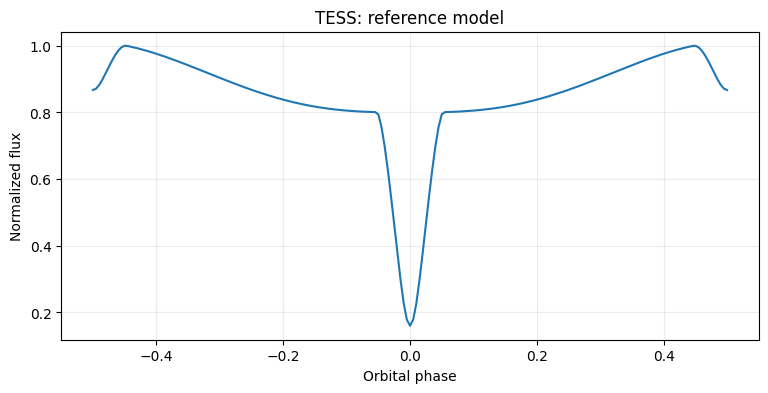

In [3]:
binary = BinarySystem.from_json(deepcopy(system_params))
observer = Observer(
    passband=[passband],
    system=binary,
)
model_phases, fluxes = observer.lc(
    phases=phases,
    normalize=True,
)
reference_flux = np.array(
    fluxes[passband],
    copy=True,
)
assert np.all(np.isfinite(reference_flux))
assert np.all(reference_flux > 0)

fig, ax = plt.subplots(
    figsize=(9, 4),
)
ax.plot(model_phases, reference_flux)
ax.set(
    xlabel='Orbital phase',
    ylabel='Normalized flux',
    title=f'{passband}: reference model',
)
ax.grid(
    alpha=0.25,
)
plt.show()

## 3. How much does the assumed limb darkening matter?

Change only the primary's TESS coefficients, keeping its bolometric coefficients and both atmosphere models fixed. This isolates a passband LD sensitivity experiment. The two curves are independently normalized; their difference is a shape difference, not an absolute flux difference. Coefficients should ultimately come from a suitable atmosphere calculation or observational constraints.

2026-11-05 22:39:56,553 - 97607 - elisa.binary_system.system - INFO: initialising object BinarySystem
2026-11-05 22:39:56,555 - 97607 - elisa.binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2026-11-05 22:39:56,556 - 97607 - elisa.observer.observer - INFO: initialising Observer instance
2026-11-05 22:39:56,557 - 97607 - elisa.observer.observer - INFO: observation is running
2026-11-05 22:39:56,665 - 97607 - elisa.observer.observer - INFO: observation finished


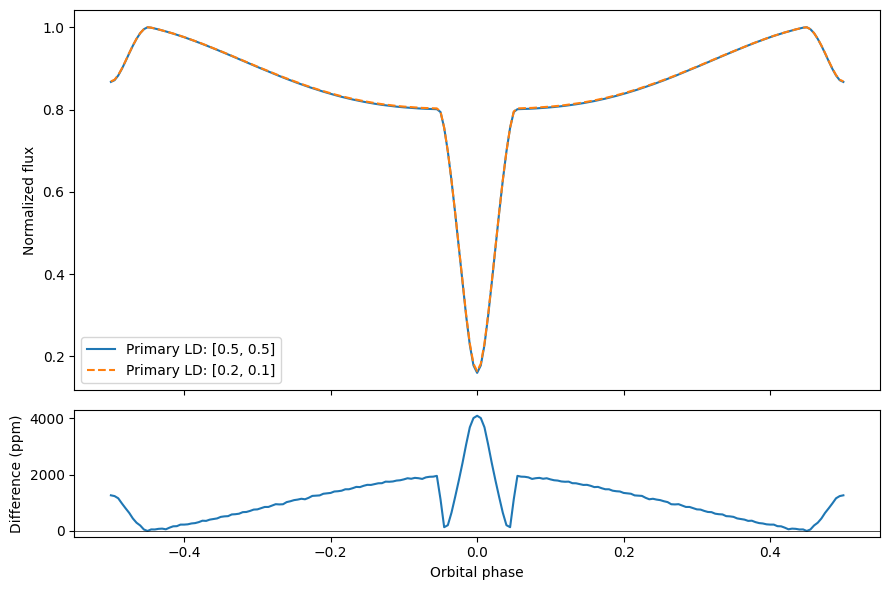

Maximum absolute shape difference: 4083.9 ppm


In [4]:
alternative_params = deepcopy(system_params)
alternative_params['primary']['limb_darkening_coefficients'][passband] = [0.2, 0.1]
alternative_observer = Observer(
    passband=[passband],
    system=BinarySystem.from_json(alternative_params),
)
_, alternative_fluxes = alternative_observer.lc(
    phases=phases,
    normalize=True,
)
alternative_flux = alternative_fluxes[passband]
difference = alternative_flux - reference_flux
assert np.all(np.isfinite(alternative_flux))

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 6),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]},
)
axes[0].plot(
    model_phases,
    reference_flux,
    label='Primary LD: [0.5, 0.5]',
)
axes[0].plot(
    model_phases,
    alternative_flux,
    '--',
    label='Primary LD: [0.2, 0.1]',
)
axes[0].set_ylabel('Normalized flux')
axes[0].legend()
axes[1].plot(model_phases, 1e6 * difference)
axes[1].axhline(
    0,
    color='black',
    linewidth=0.5,
)
axes[1].set(
    xlabel='Orbital phase',
    ylabel='Difference (ppm)',
)
fig.tight_layout()
plt.show()
print(f'Maximum absolute shape difference: {1e6 * np.max(np.abs(difference)):.1f} ppm')

Look at ingress, egress and eclipse depth as well as the maximum difference. LD changes can mimic changes in geometry; a good fit alone does not establish that the chosen atmosphere and LD are physically appropriate.

## 4. Pass the same assumptions to a fitting task

Create reproducible synthetic TESS observations with 500 ppm Gaussian noise. These are a demonstration dataset generated from the reference model, not independent evidence for it. Phases and relative flux are dimensionless; errors are in the same flux units.

`LCBinaryAnalyticsTask` takes `atmosphere_models` (plural) and forwards the component mapping to the fitter as `atmosphere_model`. Atmosphere strings belong here, outside the numeric fitting parameters; selecting `bb` does not change the CK04 numerical fitting defaults or their bounds.

In [5]:
rng = np.random.default_rng(14)
flux_sigma = 5e-4
synthetic_data = LCData(
    x_data=model_phases.copy(),
    y_data=reference_flux + rng.normal(0, flux_sigma, reference_flux.size),
    y_err=np.full(reference_flux.shape, flux_sigma),
    x_unit=u.dimensionless_unscaled,
    y_unit=u.dimensionless_unscaled,
)
atmosphere_models = {
    component: system_params[component]['atmosphere']
    for component in ('primary', 'secondary')
}
custom_ld = {
    component: deepcopy(system_params[component]['limb_darkening_coefficients'])
    for component in ('primary', 'secondary')
}
task = LCBinaryAnalyticsTask(
    data={passband: synthetic_data},
    method='least_squares',
    expected_morphology='detached',
    atmosphere_models=atmosphere_models,
    limb_darkening_coefficients=custom_ld,
)
print(f'Prepared {len(model_phases)} synthetic {passband} observations for fitting.')

Prepared 201 synthetic TESS observations for fitting.


This cell constructs the task; it does not run an optimizer. Continue with demo 12 for initial numeric parameter definitions, bounds, `task.fit(...)`, residuals and uncertainty assessment. Use the same passband and atmosphere/LD assumptions throughout; the `system_params` dictionary above is a forward-model definition, not a fitting-parameter definition. For a hot primary, review temperature starting values and bounds explicitly.

## 5. Optional: use a grid atmosphere for the secondary

The original mixed model uses `bb` with custom LD for the hot primary and `ck04` with interpolated LD for the cooler secondary. Enable the cell below only after configuring `CK04_ATM_TABLES` and `LD_TABLES` (see demo 08). Use `K93_ATM_TABLES` for `k93`. Directory existence alone does not guarantee grid coverage; local surface values and every requested passband must be supported.

In [6]:
RUN_GRID_EXAMPLE = False
if RUN_GRID_EXAMPLE:
    mixed_params = deepcopy(system_params)
    mixed_params['secondary']['atmosphere'] = 'ck04'
    mixed_params['secondary'].pop('limb_darkening_coefficients')
    mixed_observer = Observer(
        passband=[passband],
        system=BinarySystem.from_json(mixed_params),
    )
    mixed_observer.lc(
        phases=phases,
        normalize=True,
    )
    mixed_observer.plot.phase_curve()

## Troubleshooting and next steps

- **Missing atmosphere files:** configure the selected grid's tables, or deliberately use the black-body approximation.
- **LD interpolation outside the grid:** `bb` alone does not fix this. Supply custom LD for the affected component or choose parameters supported by the tables.
- **Missing passband coefficients:** add both `bolometric` and all observed filters for each component using custom LD. Filter names must match the `Observer`/task data keys exactly.
- **Wrong vector length or law mismatch:** configure the law before constructing stars/tasks and supply coefficients in that law's order. Rebuild after changing the law.
- **Adding another filter:** provide its coefficients for both stars before changing the observer and the task data dictionary.

Before applying this to observations, justify the atmosphere approximation, coefficients and their sensitivity, and check the residuals. This notebook demonstrates configuration and sensitivity, not a validated inference of stellar parameters.

Restore the previous global law after finishing. Rerun from the setup cell before reusing these objects.

In [7]:
settings.configure(
    LIMB_DARKENING_LAW=original_ld_law,
)